# XGBoost hyperparameter tuning for CEPDB → HOPV15 transfer

This version chooses hyperparameters using cross-validation on a HOPV15 tuning subset, while every model is trained on CEPDB only. A separate HOPV15 holdout is reserved for the final score.

**Important:** this uses HOPV15 labels for model selection, so it is no longer a zero-shot evaluation. Do not use the final holdout to adjust parameters. Because HOPV15 is small, scores can vary with the split; report the split seed and compare the original model on these exact same holdout molecules.


In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, KFold, ParameterSampler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from rdkit_and_test_functions import prepare_test_data


In [2]:
X_train = joblib.load("X_train.pkl")
y_train = joblib.load("y_train.pkl")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (24993, 11)
y_train shape: (24993,)


In [3]:
param_dist = {
    "n_estimators": [100, 200, 400, 800],
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "min_child_weight": [1, 3, 5, 10],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [1, 5, 10, 20],
    "gamma": [0, 0.1, 0.3, 1]
}

# 20 randomly sampled parameter combinations. Increase n_iter for a broader search.
candidate_params = list(ParameterSampler(
    param_dist,
    n_iter=20,
    random_state=42
))


In [4]:
# Load HOPV15 once, then split it into a tuning portion and a final holdout.
# The final holdout is not used to select hyperparameters.
X_hopv, y_hopv, hopv_smiles = prepare_test_data(X_train.columns)

X_hopv = X_hopv[X_train.columns].reset_index(drop=True)
y_hopv = np.asarray(y_hopv)
hopv_smiles = np.asarray(hopv_smiles)

all_indices = np.arange(len(X_hopv))
tune_idx, final_idx = train_test_split(
    all_indices,
    test_size=0.50,
    random_state=42
)

X_tune = X_hopv.iloc[tune_idx].reset_index(drop=True)
y_tune = y_hopv[tune_idx]
X_final = X_hopv.iloc[final_idx].reset_index(drop=True)
y_final = y_hopv[final_idx]
final_smiles = hopv_smiles[final_idx]

print("CEPDB training shape:", X_train.shape)
print("HOPV15 tuning shape:", X_tune.shape)
print("HOPV15 final test shape:", X_final.shape)


X column names:
smiles

y column name:
electrochemical_gap
X_test shape: (212, 11)
y_test shape: (212,)
CEPDB training shape: (24993, 11)
HOPV15 tuning shape: (106, 11)
HOPV15 final test shape: (106, 11)


In [5]:
# Select parameters by cross-validation on HOPV15 tuning samples.
# Each fold's validation samples are held out; every model is trained on CEPDB only.
cv = KFold(n_splits=3, shuffle=True, random_state=42)
search_results = []

for candidate_num, params in enumerate(candidate_params, start=1):
    fold_maes = []

    for train_fold_idx, val_fold_idx in cv.split(X_tune):
        X_val = X_tune.iloc[val_fold_idx]
        y_val = y_tune[val_fold_idx]

        model = XGBRegressor(
            **params,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
        model.fit(X_train, y_train)
        val_pred = model.predict(X_val)
        fold_maes.append(mean_absolute_error(y_val, val_pred))

    search_results.append({
        "params": params,
        "cv_mae": float(np.mean(fold_maes)),
        "cv_mae_std": float(np.std(fold_maes))
    })

    print(
        f"Candidate {candidate_num}/{len(candidate_params)} | "
        f"Mean HOPV15 CV MAE: {np.mean(fold_maes):.4f} eV"
    )

search_results = sorted(search_results, key=lambda row: row["cv_mae"])
best_result = search_results[0]
best_params = best_result["params"]

print("\nBest XGBoost Parameters for HOPV15 transfer")
print("-------------------------------------------")
for parameter, value in best_params.items():
    print(f"{parameter}: {value}")

print(f"\nMean HOPV15 CV MAE: {best_result['cv_mae']:.4f} eV")
print(f"CV MAE standard deviation: {best_result['cv_mae_std']:.4f} eV")


Candidate 1/20 | Mean HOPV15 CV MAE: 0.4396 eV
Candidate 2/20 | Mean HOPV15 CV MAE: 0.4876 eV
Candidate 3/20 | Mean HOPV15 CV MAE: 0.3922 eV
Candidate 4/20 | Mean HOPV15 CV MAE: 0.3764 eV
Candidate 5/20 | Mean HOPV15 CV MAE: 0.4155 eV
Candidate 6/20 | Mean HOPV15 CV MAE: 0.3691 eV
Candidate 7/20 | Mean HOPV15 CV MAE: 0.4044 eV
Candidate 8/20 | Mean HOPV15 CV MAE: 0.4801 eV
Candidate 9/20 | Mean HOPV15 CV MAE: 0.4921 eV
Candidate 10/20 | Mean HOPV15 CV MAE: 0.4541 eV
Candidate 11/20 | Mean HOPV15 CV MAE: 0.3469 eV
Candidate 12/20 | Mean HOPV15 CV MAE: 0.4694 eV
Candidate 13/20 | Mean HOPV15 CV MAE: 0.4451 eV
Candidate 14/20 | Mean HOPV15 CV MAE: 0.2956 eV
Candidate 15/20 | Mean HOPV15 CV MAE: 0.4294 eV
Candidate 16/20 | Mean HOPV15 CV MAE: 0.3872 eV
Candidate 17/20 | Mean HOPV15 CV MAE: 0.4349 eV
Candidate 18/20 | Mean HOPV15 CV MAE: 0.2899 eV
Candidate 19/20 | Mean HOPV15 CV MAE: 0.4017 eV
Candidate 20/20 | Mean HOPV15 CV MAE: 0.3139 eV

Best XGBoost Parameters for HOPV15 transfer
----

In [6]:
# Fit the selected model on all CEPDB data and evaluate once on the untouched HOPV15 holdout.
best_xgb = XGBRegressor(
    **best_params,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)
best_xgb.fit(X_train, y_train)

print(best_xgb)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.6, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=0, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.01, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=1, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=-1,
             num_parallel_tree=None, random_state=42, ...)


In [7]:
X_test = X_final
y_test = y_final
test_smiles = final_smiles

print("Final HOPV15 test shape:", X_test.shape)
print("Final HOPV15 target shape:", y_test.shape)


Final HOPV15 test shape: (106, 11)
Final HOPV15 target shape: (106,)


In [8]:
y_pred = best_xgb.predict(X_test)


In [9]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("HOPV15 Holdout Results — XGBoost Tuned for Transfer")
print("---------------------------------------------------")
print(f"MAE : {mae:.4f} eV")
print(f"RMSE: {rmse:.4f} eV")
print(f"R²  : {r2:.4f}")


HOPV15 Holdout Results — XGBoost Tuned for Transfer
---------------------------------------------------
MAE : 0.2600 eV
RMSE: 0.3632 eV
R²  : -0.0686


In [10]:
results = pd.DataFrame({
    "SMILES": test_smiles,
    "Experimental_Gap": y_test,
    "Predicted_Gap": y_pred,
    "Absolute_Error": np.abs(y_test - y_pred)
})

results.to_csv("HOPV15_predictions_xgboost_transfer_tuned.csv", index=False)
print("Final holdout predictions saved to HOPV15_predictions_xgboost_transfer_tuned.csv")


Final holdout predictions saved to HOPV15_predictions_xgboost_transfer_tuned.csv


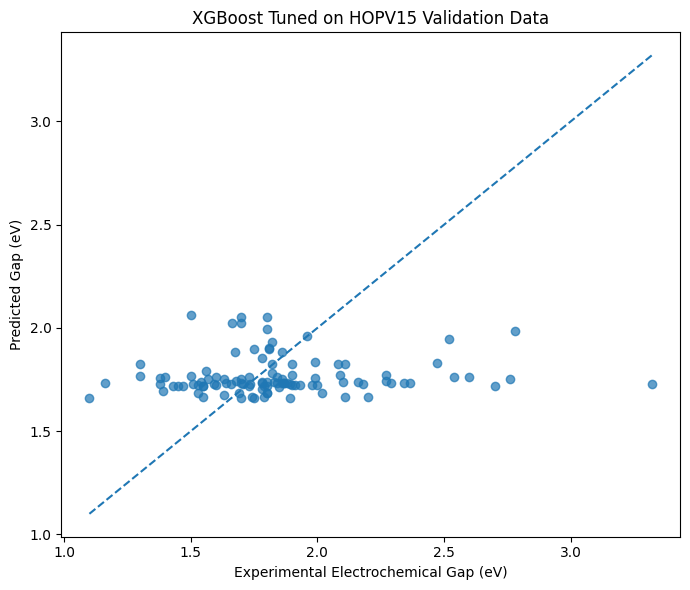

In [11]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

min_val = min(np.min(y_test), np.min(y_pred))
max_val = max(np.max(y_test), np.max(y_pred))

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("Experimental Electrochemical Gap (eV)")
plt.ylabel("Predicted Gap (eV)")
plt.title("XGBoost Tuned on HOPV15 Validation Data")
plt.tight_layout()
plt.show()
